(913000, 4) (1826,)


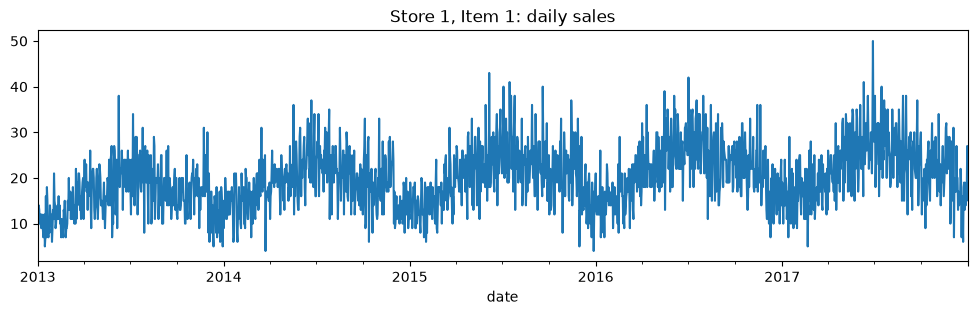

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv", parse_dates=["date"])
one = df[(df["store"] == 1) & (df["item"] == 1)].set_index("date")["sales"]
print(df.shape, one.shape)

one.plot(figsize=(12, 3), title="Store 1, Item 1: daily sales")
plt.show()

repeat last week : 6.68 | sMAPE 36.92
avg of last 4 wks: 6.11 | sMAPE 34.51


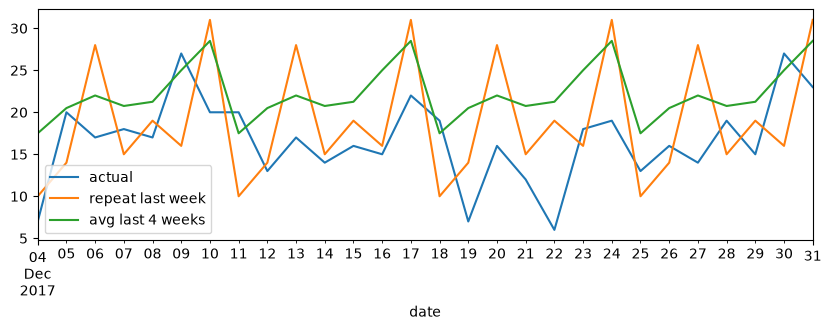

In [24]:
H = 28                                      
train, test = one[:-H], one[-H:]            

# Baseline 1: repeat the last 7 days
b1 = pd.Series(list(train[-7:]) * 4, index=test.index)

# Baseline 2: average of each weekday over the last 4 weeks
last4 = train[-28:].values.reshape(4, 7).mean(axis=0)
b2 = pd.Series(list(last4) * 4, index=test.index)

def mae(actual, forecast):                  
    return (actual - forecast).abs().mean()

def smape(actual, forecast):                
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    denom = np.abs(a) + np.abs(f)
    return 100 * np.mean(np.where(denom == 0, 0, 2 * np.abs(a - f) / denom))

print("repeat last week :", round(mae(test, b1), 2), "| sMAPE", round(smape(test, b1), 2))
print("avg of last 4 wks:", round(mae(test, b2), 2), "| sMAPE", round(smape(test, b2), 2))

test.plot(label="actual", figsize=(10, 3))
b1.plot(label="repeat last week")
b2.plot(label="avg last 4 weeks")
plt.legend(); plt.show()

In [25]:
from xgboost import XGBRegressor

d = one.to_frame("sales")
for lag in (28, 35, 42, 364):
    d[f"lag_{lag}"] = one.shift(lag)           
d["roll28"] = one.shift(H).rolling(28).mean()  
d["weekday"] = d.index.day_of_week
d["month"] = d.index.month
d["doy"] = d.index.day_of_year
d = d.dropna()

X, y = d.drop(columns="sales"), d["sales"]
X_train, y_train = X[X.index < test.index[0]], y[y.index < test.index[0]]  

model = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)
xgb_pred = pd.Series(model.predict(X.loc[test.index]), index=test.index)

print("repeat last week :", round(mae(test, b1), 2))
print("avg of last 4 wks:", round(mae(test, b2), 2))
print("XGBoost          :", round(mae(test, xgb_pred), 2))

repeat last week : 6.68
avg of last 4 wks: 6.11
XGBoost          : 3.6


In [26]:
rows = []
for k in range(4):                                    
    end = len(one) - k * H
    test_k = one.iloc[end - H:end]
    train_k = one.iloc[:end - H]

    p1 = pd.Series(list(train_k[-7:]) * 4, index=test_k.index)
    p2 = pd.Series(list(train_k[-28:].values.reshape(4, 7).mean(axis=0)) * 4, index=test_k.index)
    m = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
    m.fit(X[X.index < test_k.index[0]], y[y.index < test_k.index[0]])
    p3 = pd.Series(m.predict(X.loc[test_k.index]), index=test_k.index)

    rows.append({"window": f"{test_k.index[0].date()} to {test_k.index[-1].date()}",
                 "MAE repeat last week": mae(test_k, p1), "MAE avg last 4 wks": mae(test_k, p2), "MAE XGBoost": mae(test_k, p3),
                 "sMAPE repeat last week": smape(test_k, p1), "sMAPE avg last 4 wks": smape(test_k, p2), "sMAPE XGBoost": smape(test_k, p3)})

results = pd.DataFrame(rows).set_index("window").round(2)
results.loc["AVERAGE"] = results.mean().round(2)
results

,MAE repeat last week,MAE avg last 4 wks,MAE XGBoost,sMAPE repeat last week,sMAPE avg last 4 wks,sMAPE XGBoost
window,,,,,,
2017-12-04 to 2017-12-31,6.68,6.11,3.60,36.92,34.51,23.37
2017-11-06 to 2017-12-03,5.43,4.36,4.21,24.65,20.74,20.44
2017-10-09 to 2017-11-05,4.93,4.23,3.66,23.92,19.84,17.48
2017-09-11 to 2017-10-08,5.36,4.77,4.27,23.89,21.10,19.58
AVERAGE,5.60,4.87,3.94,27.35,24.05,20.22


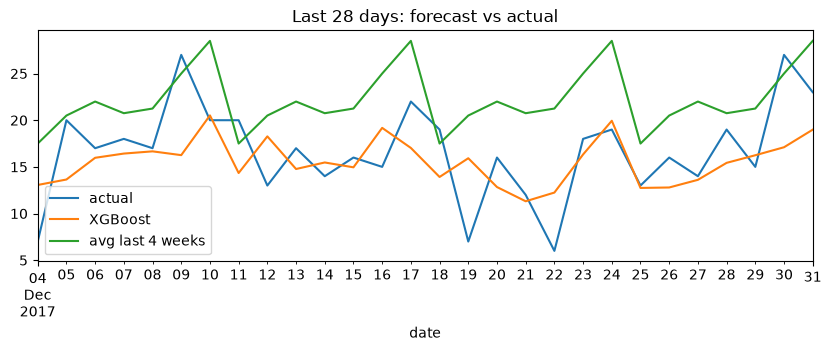

     XGBoost  avg last 4 wks
Mon     4.26            4.75
Tue     5.94            6.50
Wed     1.70            6.00
Thu     1.82            5.00
Fri     2.22            7.75
Sat     6.62            5.25
Sun     2.61            7.50


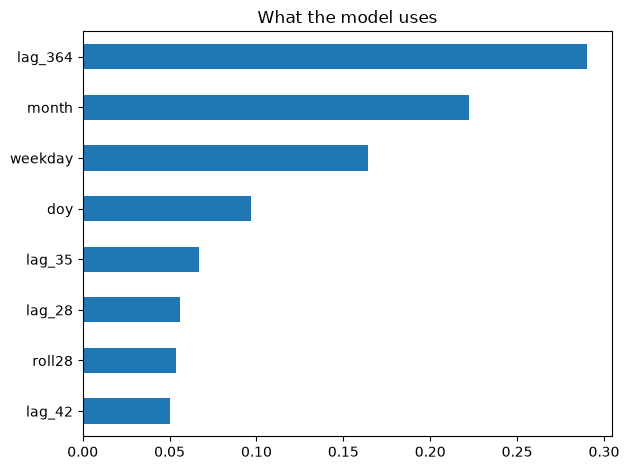

In [27]:
test.plot(label="actual", figsize=(10, 3))
xgb_pred.plot(label="XGBoost")
b2.plot(label="avg last 4 weeks")
plt.legend(); plt.title("Last 28 days: forecast vs actual"); plt.show()

err = pd.DataFrame({"weekday": test.index.day_of_week,
                    "XGBoost": (test - xgb_pred).abs(),
                    "avg last 4 wks": (test - b2).abs()})
by_day = err.groupby("weekday").mean().round(2)
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(by_day)

pd.Series(model.feature_importances_, index=X.columns).sort_values().plot(kind="barh", title="What the model uses")
plt.tight_layout(); plt.show()

In [28]:
import time
wide = df.pivot_table(index="date", columns=["store", "item"], values="sales")   # days x 500 series

all_df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
g = all_df.groupby(["store", "item"])["sales"]
for lag in (28, 35, 42, 364):
    all_df[f"lag_{lag}"] = g.shift(lag)
all_df["roll28"] = g.transform(lambda s: s.shift(H).rolling(28).mean())
all_df["weekday"] = all_df["date"].dt.day_of_week
all_df["month"] = all_df["date"].dt.month
all_df["doy"] = all_df["date"].dt.day_of_year
all_df = all_df.dropna()
feats = [c for c in all_df.columns if c not in ("date", "sales")]

rows, t0 = [], time.time()
for k in range(4):
    end = len(wide) - k * H
    test_days = wide.index[end - H:end]
    actual = wide.loc[test_days].values                                        # 28 days x 500 series

    p1 = np.tile(wide.iloc[end - H - 7:end - H].values, (4, 1))
    last4_all = wide.iloc[end - H - 28:end - H].values.reshape(4, 7, -1).mean(axis=0)
    p2 = np.tile(last4_all, (4, 1))

    tr = all_df[all_df["date"] < test_days[0]]
    te = all_df[all_df["date"].isin(test_days)]
    m = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
    m.fit(tr[feats], tr["sales"])
    p3 = m.predict(te[feats])

    rows.append({"window": f"{test_days[0].date()} to {test_days[-1].date()}",
                 "MAE repeat last week": np.abs(actual - p1).mean(), "MAE avg last 4 wks": np.abs(actual - p2).mean(),
                 "MAE XGBoost (all series)": np.abs(te["sales"].values - p3).mean(),
                 "sMAPE repeat last week": smape(actual, p1), "sMAPE avg last 4 wks": smape(actual, p2),
                 "sMAPE XGBoost (all series)": smape(te["sales"].values, p3)})
    print("window", k, "done after", round(time.time() - t0), "seconds")

res_all = pd.DataFrame(rows).set_index("window").round(2)
res_all.loc["AVERAGE"] = res_all.mean().round(2)
res_all

window 0 done after 6 seconds
window 1 done after 12 seconds
window 2 done after 19 seconds
window 3 done after 28 seconds


,MAE repeat last week,MAE avg last 4 wks,MAE XGBoost (all series),sMAPE repeat last week,sMAPE avg last 4 wks,sMAPE XGBoost (all series)
window,,,,,,
2017-12-04 to 2017-12-31,12.81,15.81,5.40,27.78,31.89,13.88
2017-11-06 to 2017-12-03,10.11,8.34,6.23,18.55,15.33,11.83
2017-10-09 to 2017-11-05,8.58,7.10,6.14,16.86,13.60,12.01
2017-09-11 to 2017-10-08,8.78,7.77,6.25,16.36,14.13,11.85
AVERAGE,10.07,9.75,6.00,19.89,18.74,12.39


In [29]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def window_mae(params, k):
    end = len(one) - k * H
    test_k = one.iloc[end - H:end]
    m = XGBRegressor(random_state=42, **params).fit(X[X.index < test_k.index[0]], y[y.index < test_k.index[0]])
    return mae(test_k, pd.Series(m.predict(X.loc[test_k.index]), index=test_k.index))

def objective(trial):
    params = dict(n_estimators=trial.suggest_int("n_estimators", 100, 500),
                  max_depth=trial.suggest_int("max_depth", 2, 6),
                  learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True))
    return np.mean([window_mae(params, k) for k in (1, 2, 3)])        # windows 1-3 only

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20)

default = dict(n_estimators=300, max_depth=4, learning_rate=0.05)
print("best params:", study.best_params)
print("final window  default:", round(window_mae(default, 0), 2), "| tuned:", round(window_mae(study.best_params, 0), 2))

best params: {'n_estimators': 423, 'max_depth': 2, 'learning_rate': 0.10261451916475542}
final window  default: 3.6 | tuned: 3.72


In [16]:
import asyncio, sys
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

async def main():
    params = StdioServerParameters(command=sys.executable, args=["forecast_server.py"])
    async with stdio_client(params, errlog=sys.__stderr__) as (r, w):
        async with ClientSession(r, w) as s:
            await s.initialize()
            print([t.name for t in (await s.list_tools()).tools])
            out = await s.call_tool("forecast_sales", {"store": 1, "item": 1, "weeks": 2})
            print(out.content[0].text)
            bad = await s.call_tool("forecast_sales", {"store": 99, "item": 1, "weeks": 2})
            print(bad.content[0].text)

await main()


['forecast_sales']
{
  "store": 1,
  "item": 1,
  "daily_forecast": {
    "2018-01-01": 13.0,
    "2018-01-02": 14.9,
    "2018-01-03": 14.0,
    "2018-01-04": 17.4,
    "2018-01-05": 17.6,
    "2018-01-06": 19.6,
    "2018-01-07": 20.7,
    "2018-01-08": 12.9,
    "2018-01-09": 12.1,
    "2018-01-10": 16.1,
    "2018-01-11": 13.5,
    "2018-01-12": 15.8,
    "2018-01-13": 14.7,
    "2018-01-14": 23.8
  },
  "weekly_totals": [
    117,
    109
  ]
}
{
  "error": "unknown store or item (store 1-10, item 1-50)"
}
